In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO
%matplotlib inline

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [15]:
#1. Виведення перших п'яти рядків таблиці за допомогою методу head()

In [18]:
url = "https://uk.wikipedia.org/wiki/Коефіцієнт_народжуваності_в_регіонах_України"
headers = {
    "User-Agent": "Mozilla/5.0",
    "Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}
MATCH = "Коефіцієнт народжуваності в регіонах України"

try:
    response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()
    html = response.text
except requests.RequestException as e:
    print("Вікіпедія недоступна, читаю локальний файл:", e)
    with open("population.html", encoding="utf-8") as f:
        html = f.read()

df = pd.read_html(StringIO(html), match=MATCH, thousands=".", decimal=",")[0]
display(df.head())

Вікіпедія недоступна, читаю локальний файл: 403 Client Error: Too many requests. Please respect our robot policy https://w.wiki/4wJS. (dd12474) for url: https://uk.wikipedia.org/wiki/%D0%9A%D0%BE%D0%B5%D1%84%D1%96%D1%86%D1%96%D1%94%D0%BD%D1%82_%D0%BD%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D0%BE%D1%81%D1%82%D1%96_%D0%B2_%D1%80%D0%B5%D0%B3%D1%96%D0%BE%D0%BD%D0%B0%D1%85_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—


In [19]:
#2. Визначення кількості рядків та стовпців у датафреймі

In [20]:
print(f"Розмір датафрейму: {df.shape}")
print(f"Кількість рядків: {df.shape[0]}")
print(f"Кількість стовпців: {df.shape[1]}")

Розмір датафрейму: (28, 9)
Кількість рядків: 28
Кількість стовпців: 9


In [21]:
#3. Заміна значень порожніх значень '-' на Nan

In [22]:
df = df.replace("—", np.nan)
df.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,NaN,NaN
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,NaN


In [9]:
#4.Визначте типи всіх стовпців за допомогою dataframe.dtypes

In [10]:
print("Типи стовпців:")
print(df.dtypes)

Типи стовпців:
Регіон     object
1950      float64
1960      float64
1970      float64
1990        int64
2000        int64
2012        int64
2014       object
2019       object
dtype: object


In [11]:
#5.Заміна типу нечислових колонок на числові

In [23]:
for col in ['2014', '2019']:
    df[col] = pd.to_numeric(df[col])
df.dtypes

Регіон     object
1950      float64
1960      float64
1970      float64
1990      float64
2000      float64
2012      float64
2014      float64
2019      float64
dtype: object

In [13]:
#6.Підрахунок частки пропусків в кожній колонці

In [24]:
(df.isnull().sum() / len(df)).round(3)

Регіон    0.000
1950      0.071
1960      0.036
1970      0.036
1990      0.000
2000      0.000
2012      0.000
2014      0.071
2019      0.143
dtype: float64

In [15]:
# 7. Видалення з таблиці даних, останній рядок таблиці

In [26]:
print(f"Останній рядок перед видаленням: {df.index[-1]}")
df = df.iloc[:-1]
print(f"Розмір після видалення: {df.shape}")
print(f"Новий останній рядок: {df.index[-1]}")

Останній рядок перед видаленням: 26
Розмір після видалення: (26, 9)
Новий останній рядок: 25


In [17]:
# 8. Заміна відсутніх даних в стовпцях середніми значеннями цих стовпців (метод fillna)

In [27]:
df = df.fillna(df.drop(columns='Регіон').mean())
print('Пропусків залишилось:', df.isnull().sum().sum())
df.head()

Пропусків залишилось: 0


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,11.144,8.017391
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.900,7.600000
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.100,10.100000
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.100,7.100000
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.200,8.017391


In [19]:
# 9. Список регіонів, де рівень народжуваності у 2019 році був вищим за середній по Україні

In [20]:
col_2019 = '2019'
avg_2019 = df[col_2019].mean()
above_avg = df[df[col_2019] > avg_2019][col_2019].sort_values(ascending=False)

print(f"Середня народжуваність по Україні у 2019 р.: {avg_2019:.2f}")
print(f"\nРегіони з народжуваністю вище середньої ({len(above_avg)} регіони):")
print(above_avg.to_string())

Середня народжуваність по Україні у 2019 р.: 80.17

Регіони з народжуваністю вище середньої (9 регіони):
25    110.0
16    107.0
6     104.0
2     101.0
23     92.0
8      88.0
14     88.0
12     87.0
20     81.0


In [21]:
# 10. Регіон де була найвища народжуваність у 2014 році

In [29]:
row = df.loc[df['2014'].idxmax()]
print(row['Регіон'], row['2014'])


Рівненська 14.8


In [23]:
# 11. Стовпчикова діаграма народжуваності по регіонах у 2019 році

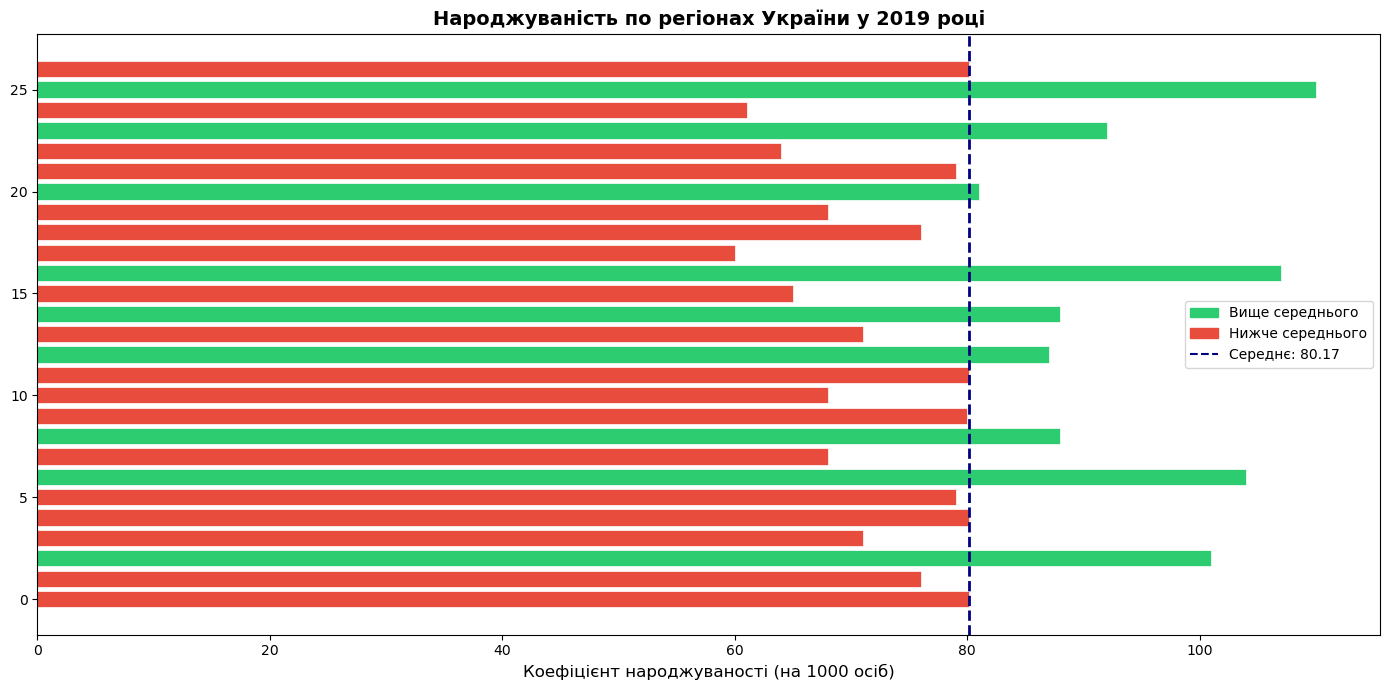

Діаграму збережено


In [24]:
fig, ax = plt.subplots(figsize=(14, 7))

data_2019 = df[col_2019].sort_values(ascending=True)
colors = ['#e74c3c' if v < avg_2019 else '#2ecc71' for v in data_2019]

bars = ax.barh(data_2019.index, data_2019.values, color=colors, edgecolor='white', linewidth=0.5)
ax.axvline(x=avg_2019, color='navy', linestyle='--', linewidth=2, label=f'Середнє: {avg_2019:.2f}')

ax.set_xlabel('Коефіцієнт народжуваності (на 1000 осіб)', fontsize=12)
ax.set_title('Народжуваність по регіонах України у 2019 році', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)

from matplotlib.patches import Patch
legend_elements = [Patch(color='#2ecc71', label='Вище середнього'),
                   Patch(color='#e74c3c', label='Нижче середнього')]
ax.legend(handles=legend_elements + [plt.Line2D([0],[0], color='navy', linestyle='--', label=f'Середнє: {avg_2019:.2f}')], fontsize=10)

plt.tight_layout()
plt.show()
print("Діаграму збережено")

In [30]:
# Додаткова візуалізація (4 графіки різного типу)

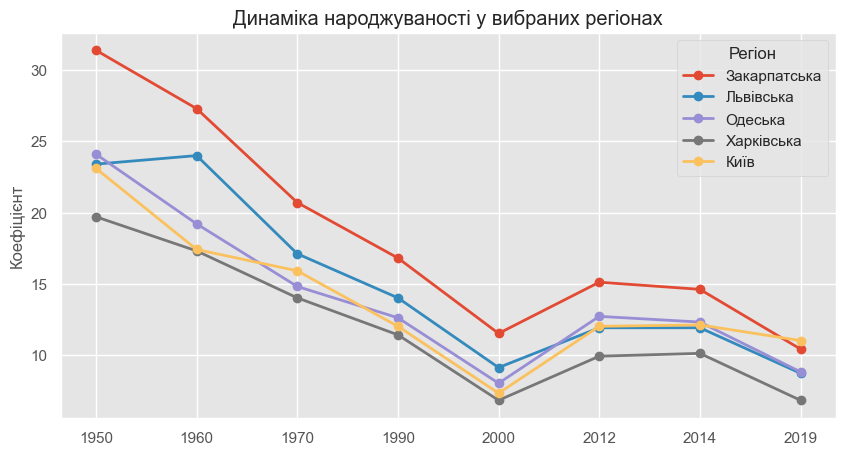

In [32]:
#1) Лінійний графік: динаміка в 5 областях

years = ['1950','1960','1970','1990','2000','2012','2014','2019']
sel = df[df['Регіон'].isin(['Київ','Львівська','Одеська','Харківська','Закарпатська'])].set_index('Регіон')[years]
plt.style.use('ggplot')
sel.T.plot(marker='o', figsize=(10,5), linewidth=2)
plt.title('Динаміка народжуваності у вибраних регіонах')
plt.ylabel('Коефіцієнт')
plt.show()
plt.style.use('default')

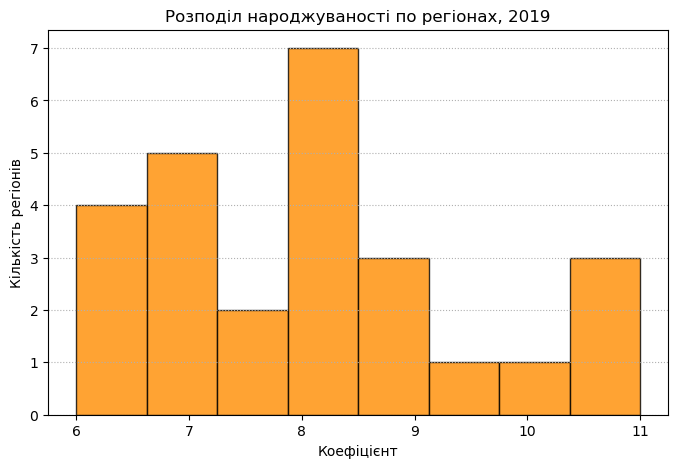

In [33]:
# 2) Гістограма розподілу 2019
plt.figure(figsize=(8,5))
plt.hist(df['2019'], bins=8, color='darkorange', edgecolor='black', alpha=.8)
plt.title('Розподіл народжуваності по регіонах, 2019')
plt.xlabel('Коефіцієнт'); plt.ylabel('Кількість регіонів')
plt.grid(axis='y', ls=':')
plt.show()

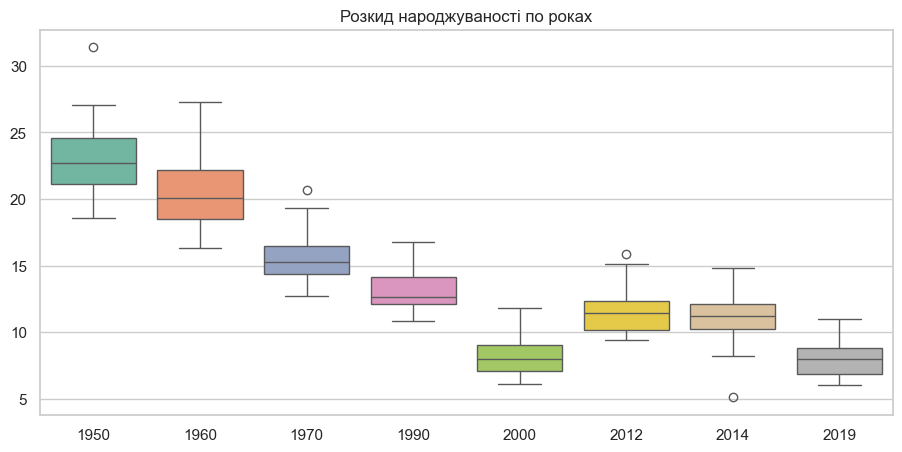

In [34]:
# 3) Boxplot по роках (seaborn)
sns.set_theme(style='whitegrid', palette='Set2')
plt.figure(figsize=(11,5))
sns.boxplot(data=df[years])
plt.title('Розкид народжуваності по роках')
plt.show()
sns.reset_orig()

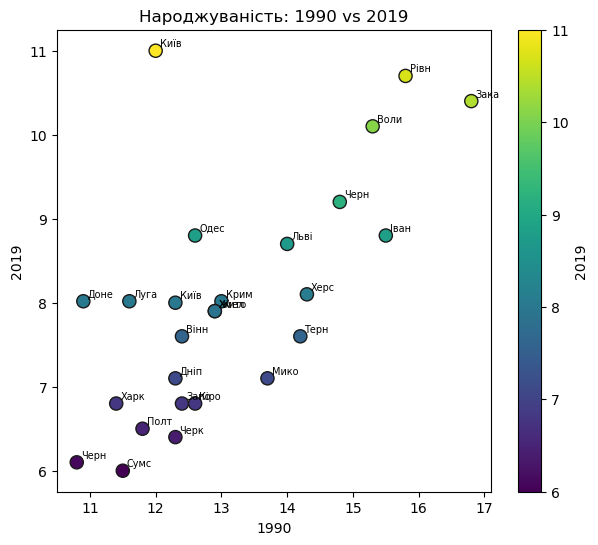

In [35]:
# 4) Scatter: 1990 vs 2019
plt.figure(figsize=(7,6))
plt.scatter(df['1990'], df['2019'], c=df['2019'], cmap='viridis', s=90, edgecolor='k')
for _, r in df.iterrows():
    plt.annotate(r['Регіон'][:4], (r['1990'], r['2019']), fontsize=7, xytext=(3,3), textcoords='offset points')
plt.colorbar(label='2019')
plt.xlabel('1990'); plt.ylabel('2019')
plt.title('Народжуваність: 1990 vs 2019')
plt.show()